# 05 — Baseline Model

**Data:** `trials.parquet` for labels and design features, `eligibility_features.parquet` from 03, and
`disease_area.parquet` from 04.

The question here is: do the eligibility features actually help predict which trials fail to enroll or
does trial design and disease area already tell us most of it?

We fit three logistic regression models, each adding one group of features:
- **A** uses design features only (phase, sponsor, masking, age limits and so on)
- **B** adds disease area. Notebook 04 found that disease area affects both strictness and failure, so B is
  the fair baseline to compare against.
- **C** adds the eligibility features from 03 (rule counts, restriction types, strictness score)

What we really care about is how much C improves on B.

We train on trials that started 2008–2016 and test on 2017–2020. PR-AUC is the main metric since only about 5% of
trials fail. We also report ROC-AUC and the Brier score.

Leaky columns like actual enrollment, enrollment type and final site and country counts are left out. We also leave out us_site, because a trial’s sites can change after it starts, and the FDA-regulated flags, because that field was only added in 2017 and is blank for most of our training trials.

## 1. Setup

Load the three tables and merge them so each labeled trial is one row.

In [4]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet")
elig = pd.read_parquet(ROOT / "data/processed/eligibility_features.parquet")
area = pd.read_parquet(ROOT / "data/processed/disease_area.parquet")

# keep labeled trials and attach eligibility + disease area features
df = trials[trials["label"].notna()].merge(elig, on="nct_id", how="left").merge(area, on="nct_id", how="left")
df["label"] = df["label"].astype(int)
print(len(df), "labeled trials, failure rate:", round(df["label"].mean() * 100, 2), "%")

164593 labeled trials, failure rate: 4.79 %


## 2. Features

Ages come in as text ("18 Years", "6 Months") so we convert them to years the same way as in 01. A blank
maximum age means there's no upper limit and a blank collaborator count means zero. The features are split into
groups so each model can add one group at a time.

In [5]:
# convert age text like "18 Years" to a number (same as 01)
UNIT_TO_YEARS = {"year": 1, "month": 1/12, "week": 1/52.18, "day": 1/365.25, "hour": 1/8766, "minute": 1/525960}

def age_years(s):
    if not isinstance(s, str):
        return np.nan
    m = re.match(r"\s*([\d.]+)\s*([a-z]+?)s?\s*$", s.lower())
    if not m or m.group(2) not in UNIT_TO_YEARS:
        return np.nan
    return float(m.group(1)) * UNIT_TO_YEARS[m.group(2)]

df["min_age_yrs"] = df["minimum_age"].map(age_years)
df["max_age_yrs"] = df["maximum_age"].map(age_years)
df["has_max_age"] = df["maximum_age"].notna().astype(int)   # missing max age = no upper limit
df["n_collaborators"] = df["n_collaborators"].fillna(0)     # missing = no collaborators

DESIGN_CAT = ["phase", "lead_sponsor_class", "primary_purpose", "allocation", "masking",
              "intervention_model", "gender", "healthy_volunteers", "has_dmc"]
DESIGN_NUM = ["number_of_arms", "n_conditions", "n_interventions", "n_collaborators",
              "min_age_yrs", "max_age_yrs", "has_max_age"]
AREA_CAT = ["primary_area", "area_source"]
AREA_NUM = [c for c in area.columns if c.startswith("area_") and c != "area_source"] + ["n_areas"]
ELIG_NUM = ["criteria_n_chars", "n_inclusion", "n_exclusion", "n_rule_types"] + \
           [c for c in elig.columns if c.startswith("rule_")]

# booleans ti numbers, categories to strings (missing becomes its own category)
df[AREA_NUM + ELIG_NUM] = df[AREA_NUM + ELIG_NUM].astype(float)
for col in DESIGN_CAT + AREA_CAT:
    df[col] = df[col].astype("object").fillna("missing").astype(str)

FEATURES = {
    "A. Design only": (DESIGN_CAT, DESIGN_NUM),
    "B. Design + disease area": (DESIGN_CAT + AREA_CAT, DESIGN_NUM + AREA_NUM),
    "C. Design + disease + eligibility": (DESIGN_CAT + AREA_CAT, DESIGN_NUM + AREA_NUM + ELIG_NUM),
}

## 3. Train/test split by year

Trials from 2008–2016 go into training and 2017–2020 into testing. This is closer to how the model would actually
be used since you'd be scoring new trials based on old ones. A random split would leak future patterns into
training and make the results look better than they are.

In [6]:
# train on older trials, test on newer ones
train = df[df["start_year"] <= 2016]
test = df[df["start_year"] >= 2017]

print("train:", len(train), "trials,", train["label"].sum(), "failures")
print("test: ", len(test), "trials,", test["label"].sum(), "failures")

train: 106860 trials, 5073 failures
test:  57733 trials, 2813 failures


## 4. Fit the models

All three models use the same setup: categories get one-hot encoded, missing numbers are filled with the median and
scaled and then a regularized logistic regression is fit. That way the only thing changing between A, B and C
is which features go in.

In [7]:
def make_model(cat_cols, num_cols):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat_cols),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=3000))])

fitted, preds = {}, {}
for name, (cat, num) in FEATURES.items():
    fitted[name] = make_model(cat, num).fit(train[cat + num], train["label"])
    preds[name] = fitted[name].predict_proba(test[cat + num])[:, 1]   # predicted risk

## 5. Test-set results

- **PR-AUC:** higher is better. Guessing randomly would get about 0.05, the failure rate.
- **ROC-AUC:** 0.5 is random.
- **Brier score:** lower is better. It shows how close the predicted risks are to what actually happened.

In [8]:
y_test = test["label"].to_numpy()

results = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_test, p),
           "ROC-AUC": roc_auc_score(y_test, p),
           "Brier": brier_score_loss(y_test, p)}
    for name, p in preds.items()
}).T
results.loc["Random guess"] = [y_test.mean(), 0.5, np.nan]
results.round(4)

,PR-AUC,ROC-AUC,Brier
A. Design only,0.1100,0.7021,0.0451
B. Design + disease area,0.1151,0.7088,0.0449
C. Design + disease + eligibility,0.1217,0.7170,0.0448
Random guess,0.0487,0.5000,NaN


## 6. Is the improvement real?

To check that the gain isn't just luck, we resample the test set 1,000 times and score both models on each sample.
If the 95% interval for the gain stays above zero, the features being added are doing something real.

In [9]:
rng = np.random.default_rng(42)

def bootstrap_gain(p_base, p_new, n_boot=1000):
    # resample test set and compare PR-AUC of both models on the same sample
    gains = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_test), len(y_test))
        gains.append(average_precision_score(y_test[idx], p_new[idx]) -
                     average_precision_score(y_test[idx], p_base[idx]))
    actual = average_precision_score(y_test, p_new) - average_precision_score(y_test, p_base)
    return pd.Series({"gain": actual, "lo": np.percentile(gains, 2.5), "hi": np.percentile(gains, 97.5)})

A, B, C = list(preds)
pd.DataFrame({
    "B vs A (disease area)": bootstrap_gain(preds[A], preds[B]),
    "C vs B (eligibility)":  bootstrap_gain(preds[B], preds[C]),
}).T.round(4)

,gain,lo,hi
B vs A (disease area),0.0052,0.0009,0.0095
C vs B (eligibility),0.0066,0.0026,0.0109


## 7. PR curves and calibration

The left plot shows how precision drops as the model tries to catch more of the failures. Higher curves are
better and the dashed line is random guessing. The right plot checks calibration: if the model says a group of
trials has a 10% risk, about 10% of them should actually fail, so the points should sit close to the diagonal.

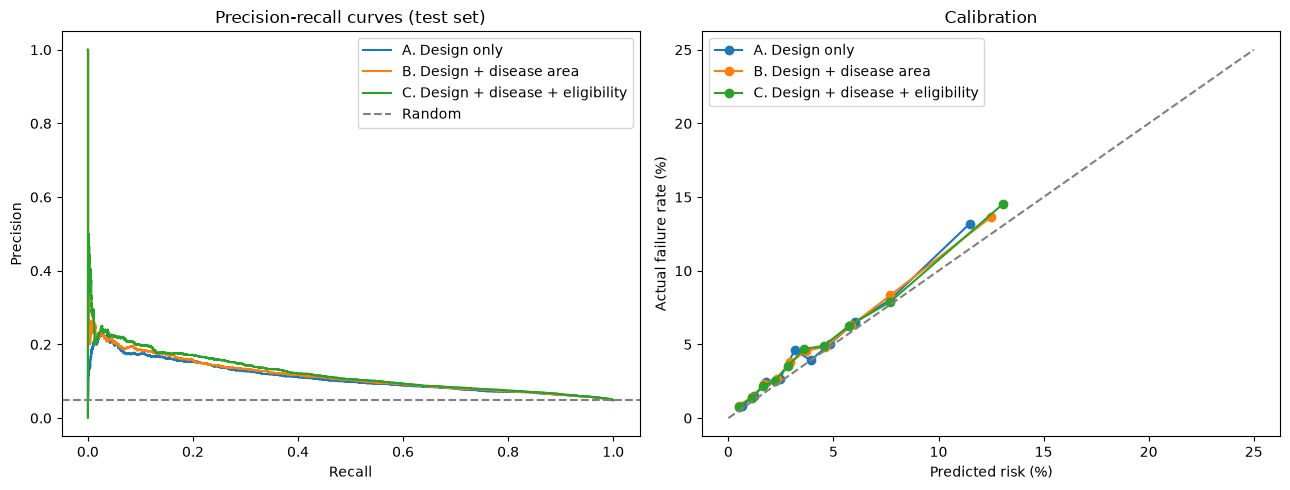

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, p in preds.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, label=name)
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred * 100, frac_pos * 100, marker="o", label=name)

axes[0].axhline(y_test.mean(), ls="--", color="gray", label="Random")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test set)")
axes[0].legend()

axes[1].plot([0, 25], [0, 25], ls="--", color="gray")   # perfect calibration line
axes[1].set(xlabel="Predicted risk (%)", ylabel="Actual failure rate (%)", title="Calibration")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG / "baseline_pr_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Which features matter most?

These are the coefficients from model C. Since the numeric features are scaled, the bars can be compared
directly. Positive values push the predicted risk up and negative values push it down. These show
what the model leans on, not what causes failure.

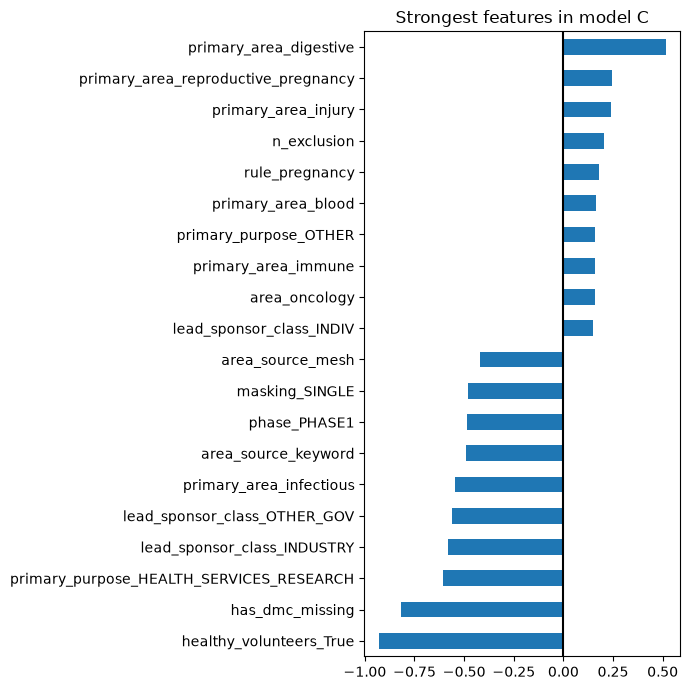

In [11]:
model_c = fitted[C]
names = model_c.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model_c.named_steps["clf"].coef_[0], index=names)
coefs.index = coefs.index.str.replace("cat__", "").str.replace("num__", "")

# 10 features that raise risk most and 10 that lower it most
top = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
top.plot.barh(figsize=(7, 7), title="Strongest features in model C")
plt.axvline(0, color="black")
plt.tight_layout()
plt.savefig(FIG / "baseline_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Save predictions

Saving the test-set predictions so the full model in 09 can be compared against these on the same trials.

In [12]:
# save so 09 can compare against the same test trials
out = test[["nct_id", "start_year", "label"]].copy()
for name, p in preds.items():
    out["pred_" + name[0]] = p
out.to_parquet(ROOT / "data/processed/baseline_predictions.parquet", index=False)

## 10. Summary

**Data**
- 164,593 labeled trials: trained on 106,860 (2008–2016, 5,073 failures) and tested on 57,733
  (2017–2020, 2,813 failures).

**Results on the test set**

| Model | PR-AUC | ROC-AUC | Brier |
|---|---|---|---|
| A. Design only | 0.110 | 0.702 | 0.0451 |
| B. Design + disease area | 0.115 | 0.709 | 0.0449 |
| C. Design + disease + eligibility | 0.122 | 0.717 | 0.0448 |
| Random guess | 0.049 | 0.500 | — |

- All three models do far better than random. Model C's PR-AUC is about 2.5 times the random baseline.
- ROC-AUC of 0.717 is close to the ~0.73 reported by Elkin and Zhu (2021).
- Adding disease area improves PR-AUC by 0.005 (95% CI 0.001–0.010).
- Adding eligibility features on top of that improves it by another 0.007 (95% CI 0.003–0.011). Since the interval
  stays above zero, eligibility rules add real information beyond trial design and disease area.

**Plots**
- Model C is slightly above the others in the precision-recall curve, mostly among the highest-risk trials. Among
  the trials it flags as riskiest, about 20% actually failed, roughly four times the overall rate.
- Calibration is good: predicted risks closely match actual failure rates, with slight underestimation for the
  riskiest trials.
- Healthy-volunteer, industry-sponsored and Phase 1 trials have lower predicted risk, matching the EDA. 
More exclusion rules and pregnancy restrictions are among the features that raise risk, matching the eligibility features and disease area notebooks.

**Limitations**
- The gains are small. This is a simple logistic regression and the eligibility features are still keyword-based.
- Labels come from the keyword stop-reason classifier, which hasn't been validated against hand labels yet.
- Coefficient sizes for disease area are hard to interpret, because the model includes both overlapping
  `primary_area` categories and `area_` flags. `has_dmc_missing` likely reflects how completely a trial was
  registered rather than a real effect. SHAP will give a clearer picture of feature importance.

**Next steps**
1. Use these models as the baseline for the full XGBoost model and SHAP.
2. Rerun once the stop-reason labels are validated and the LLM eligibility features are ready.